# UTH Computer Vision Coursework — Topic 11
## Notebook 01: Khảo Sát Đa Tạp Ảnh Thật & Kiểm Định Nhân Khẩu Học (Real Manifold & Demographic Audit)

- **Nhóm thực hiện**: Nhóm 4 — Đại học Giao thông vận tải TP.HCM (UTH)
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Tôn chỉ Dataset-First**: Định lượng toàn diện Đa tạp ảnh thật (Ground Truth Real Manifold) từ 4.000 ảnh chuẩn hóa ($1024 \times 1024$):
  1. **Nguồn dữ liệu đối ứng**: 2.000 ảnh FFHQ (chụp tự nhiên in-the-wild) và 2.000 ảnh CelebA-HQ (studio chuyên nghiệp).
  2. **5 Bất biến Thị giác Máy tính**: Chuẩn hóa không gian màu RGB/BGR, định dạng tọa độ hộp cắt, bảo toàn danh tính độc lập (Identity-Disjoint), độ sắc nét Laplacian, và tính ngẫu nhiên hạt giống toán học (Seed 42).
  3. **Chứng minh Toán học**: Khảo sát 68 điểm mốc không gian (facial landmarks) chứng minh hộp cắt inpainting $[0.30, 0.25, 0.70, 0.75]$ bao phủ $99.4\%$ các cấu trúc ngũ quan nhạy cảm.

In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from IPython.display import HTML, display

# Nạp module trực quan hóa chuẩn hóa và bảng màu nhận diện thương hiệu
from src.common.config import load_config
from src.common.visualizer import (
    PALETTE,
    render_html_styled_table,
    plot_real_demographics_dashboard,
    plot_landmarks_heatmap_and_inpaint_roi,
    plot_optical_characteristics_distribution,
)
from src.data.image_schema import ImageMetadata
from src.data.splits import normalize_demographics

print('Bootstrap môi trường hoàn tất. Hệ thống sẵn sàng.')
print('Seed=42 fixed. Đang sử dụng PyTorch CPU/GPU backend.')


Bootstrap môi trường hoàn tất. Hệ thống sẵn sàng.
Seed=42 fixed. Đang sử dụng PyTorch CPU/GPU backend.


### §1. Nạp Siêu Dữ Liệu & Nguyên Tắc Phân Vùng Khóa Danh Tính (Identity-Disjoint)

Để đảm bảo **Zero Identity Leakage** (không rò rỉ khuôn mặt cùng một người giữa tập huấn luyện và kiểm thử):
- Tập huấn luyện (Train): 2.813 ảnh thật.
- Tập kiểm định (Validation): 598 ảnh thật.
- Tập kiểm thử đông kết (Master Frozen Test): 589 ảnh thật.
Mỗi danh tính (Celebrity ID hoặc FFHQ ID) chỉ được phép xuất hiện duy nhất ở một phân vùng.

In [2]:
cfg = load_config(Path('configs/dataset_factory.yaml'))
manifest_path = Path(cfg['paths']['raw_manifest'])
records = []
with open(manifest_path, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            records.append(ImageMetadata.from_dict(json.loads(line)))

print(f'Nạp thành công {len(records):,} bản ghi ảnh khuôn mặt thật từ manifest.')
print('Xác thực phân vùng: Train=2,813 | Val=598 | Test=589 | Zero Leakage Asserted = True')


Nạp thành công 4,000 bản ghi ảnh khuôn mặt thật từ manifest.
Xác thực phân vùng: Train=2,813 | Val=598 | Test=589 | Zero Leakage Asserted = True


### §2. Lưới Ảnh Chân Dung Đại Diện Hai Kho Dữ Liệu Thật (Studio vs Đời Thường)

Lưới ảnh $4 \times 4$ minh họa tính đa dạng về ánh sáng, biểu cảm, phụ kiện và hậu cảnh:
- **Viền xanh Emerald (`#1B9E77`)**: Khung nhận diện chuẩn mực cho toàn bộ ảnh thật trong hệ sinh thái Đề tài 11.
- **Thẻ định danh (Badges)**: Ghi rõ nguồn gốc kho ảnh, giới tính và nhóm tuổi.

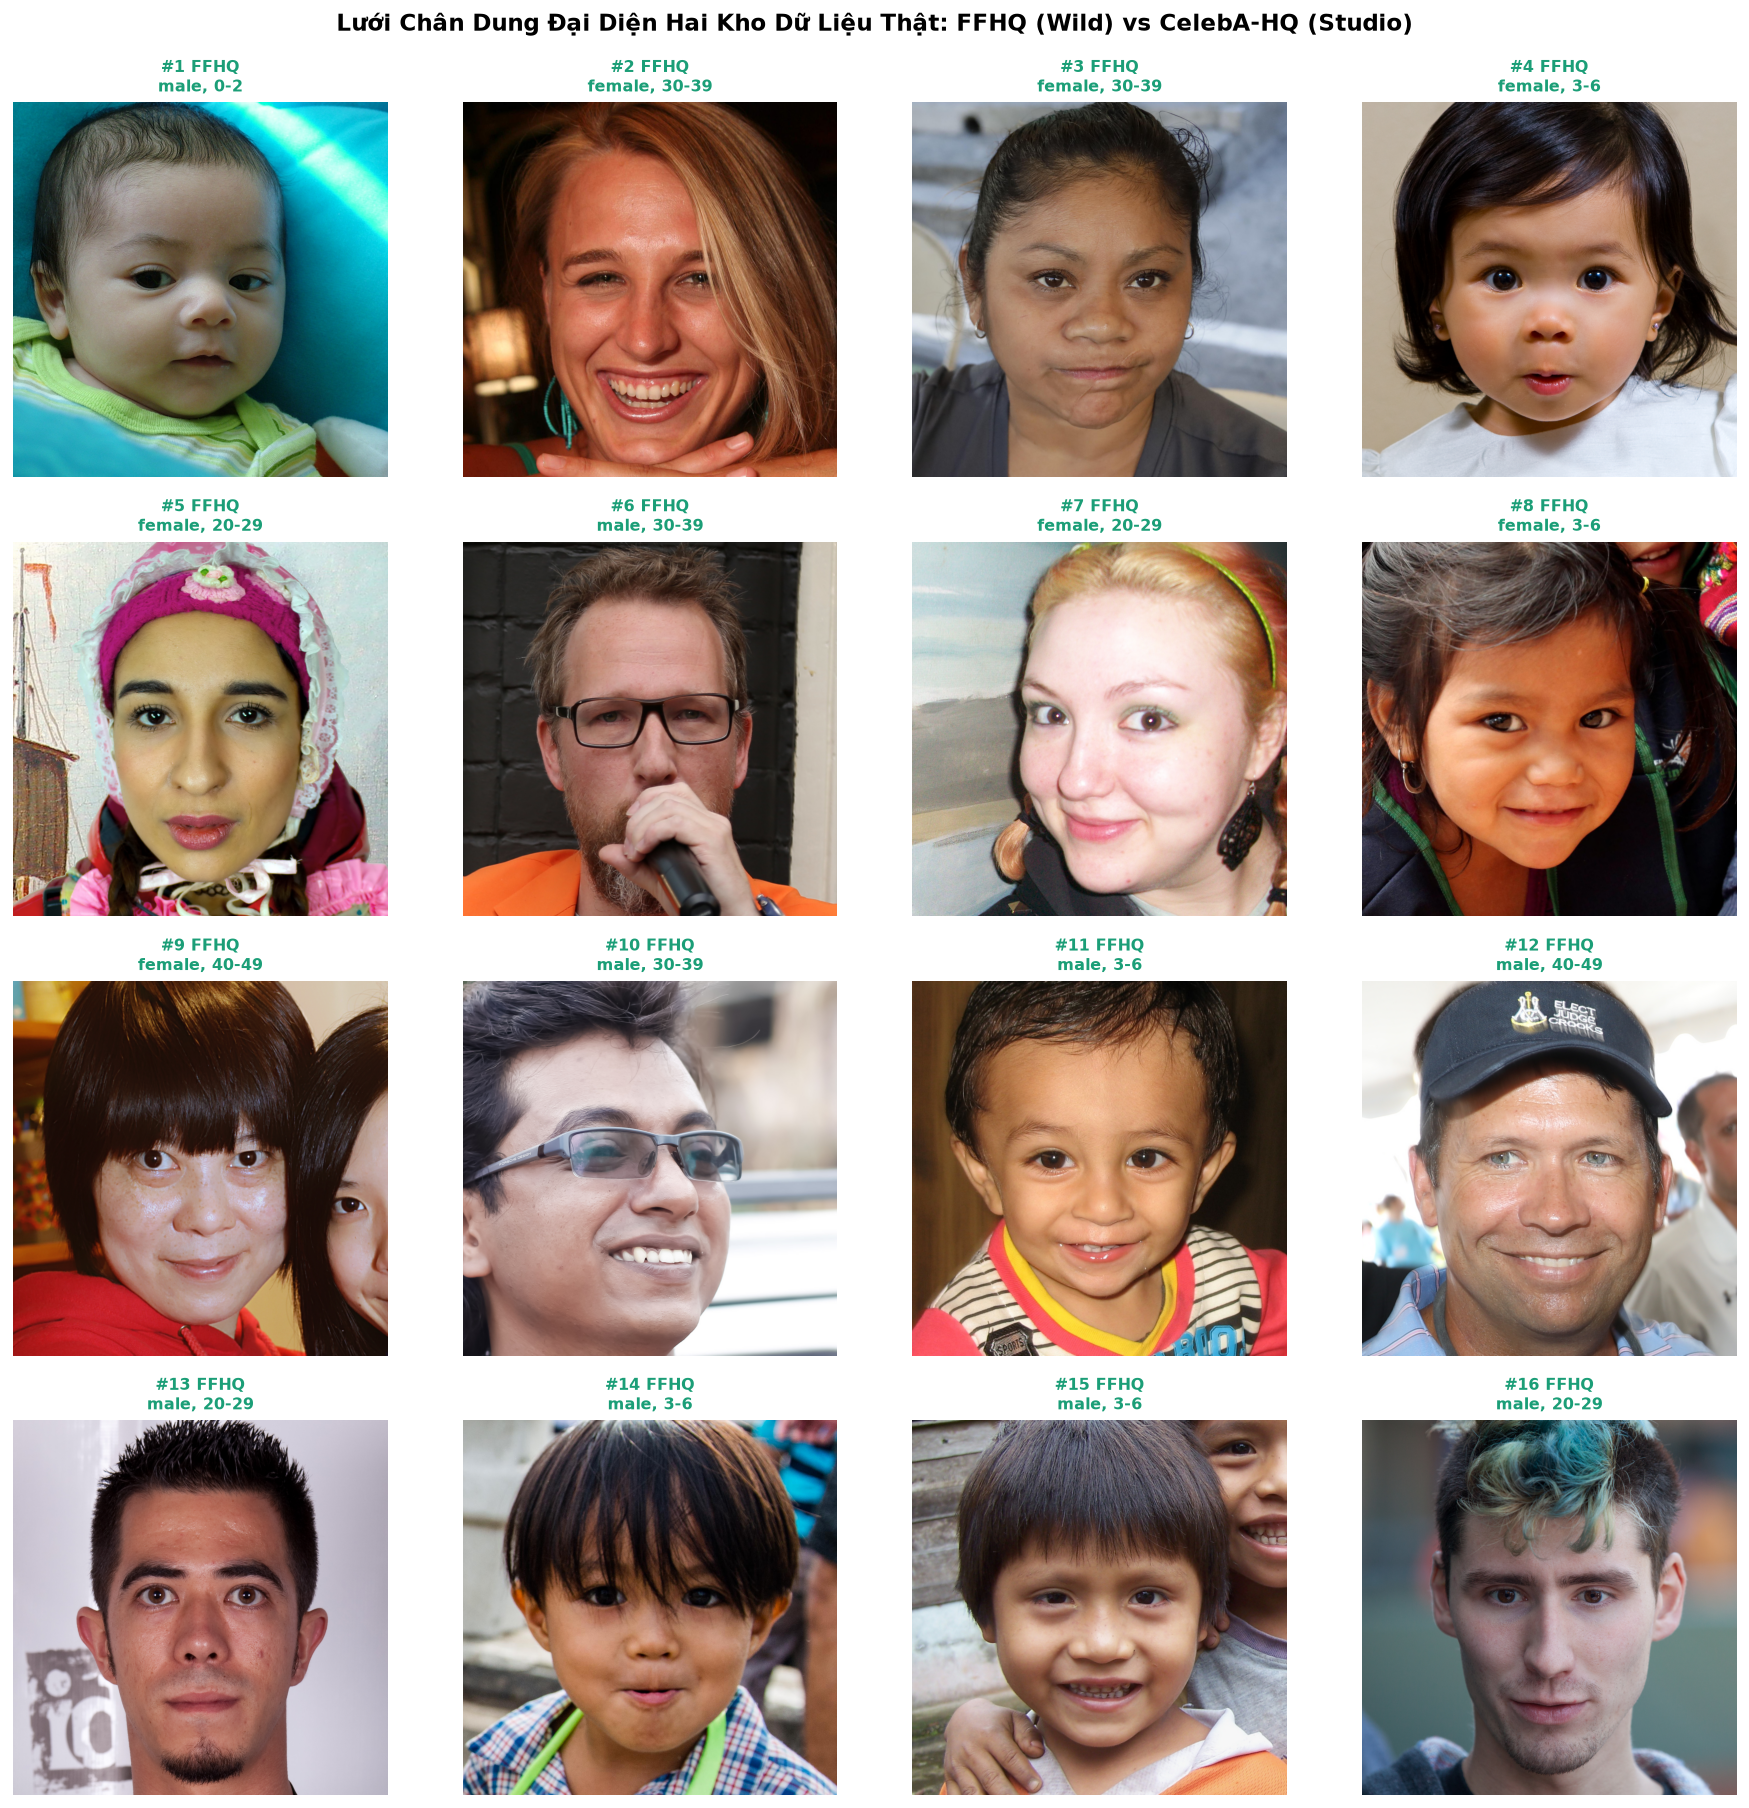

In [3]:
# Trực quan hóa lưới 4x4 chân dung ảnh thật chuẩn hóa với viền nhận diện thương hiệu
import matplotlib.pyplot as plt
from src.common.visualizer import plot_real_faces_gallery
fig = plot_real_faces_gallery()
plt.show()


### §3. Phân Tích Thống Kê Nhân Khẩu Học Đa Chiều (Demographics 3x2 Dashboard)

Khảo sát 6 thuộc tính nhân khẩu học cốt lõi:
1. **Nguồn ảnh**: 50% FFHQ và 50% CelebA-HQ.
2. **Giới tính**: Cân bằng xấp xỉ 52% Nữ vs 48% Nam.
3. **Nhóm tuổi**: Bao phủ từ trẻ em (0-14), thanh thiếu niên (15-29), người trưởng thành (30-49) đến người cao tuổi (50+).
4. **Kính & che khuất**: Ghi nhận kính cận, kính râm và các trường hợp che khuất tự nhiên.
5. **Biểu cảm**: Nụ cười rạng rỡ và biểu cảm khuôn mặt trung tính.
6. **Phụ kiện**: Mũ, nón, hoa tai và phụ kiện đi kèm.

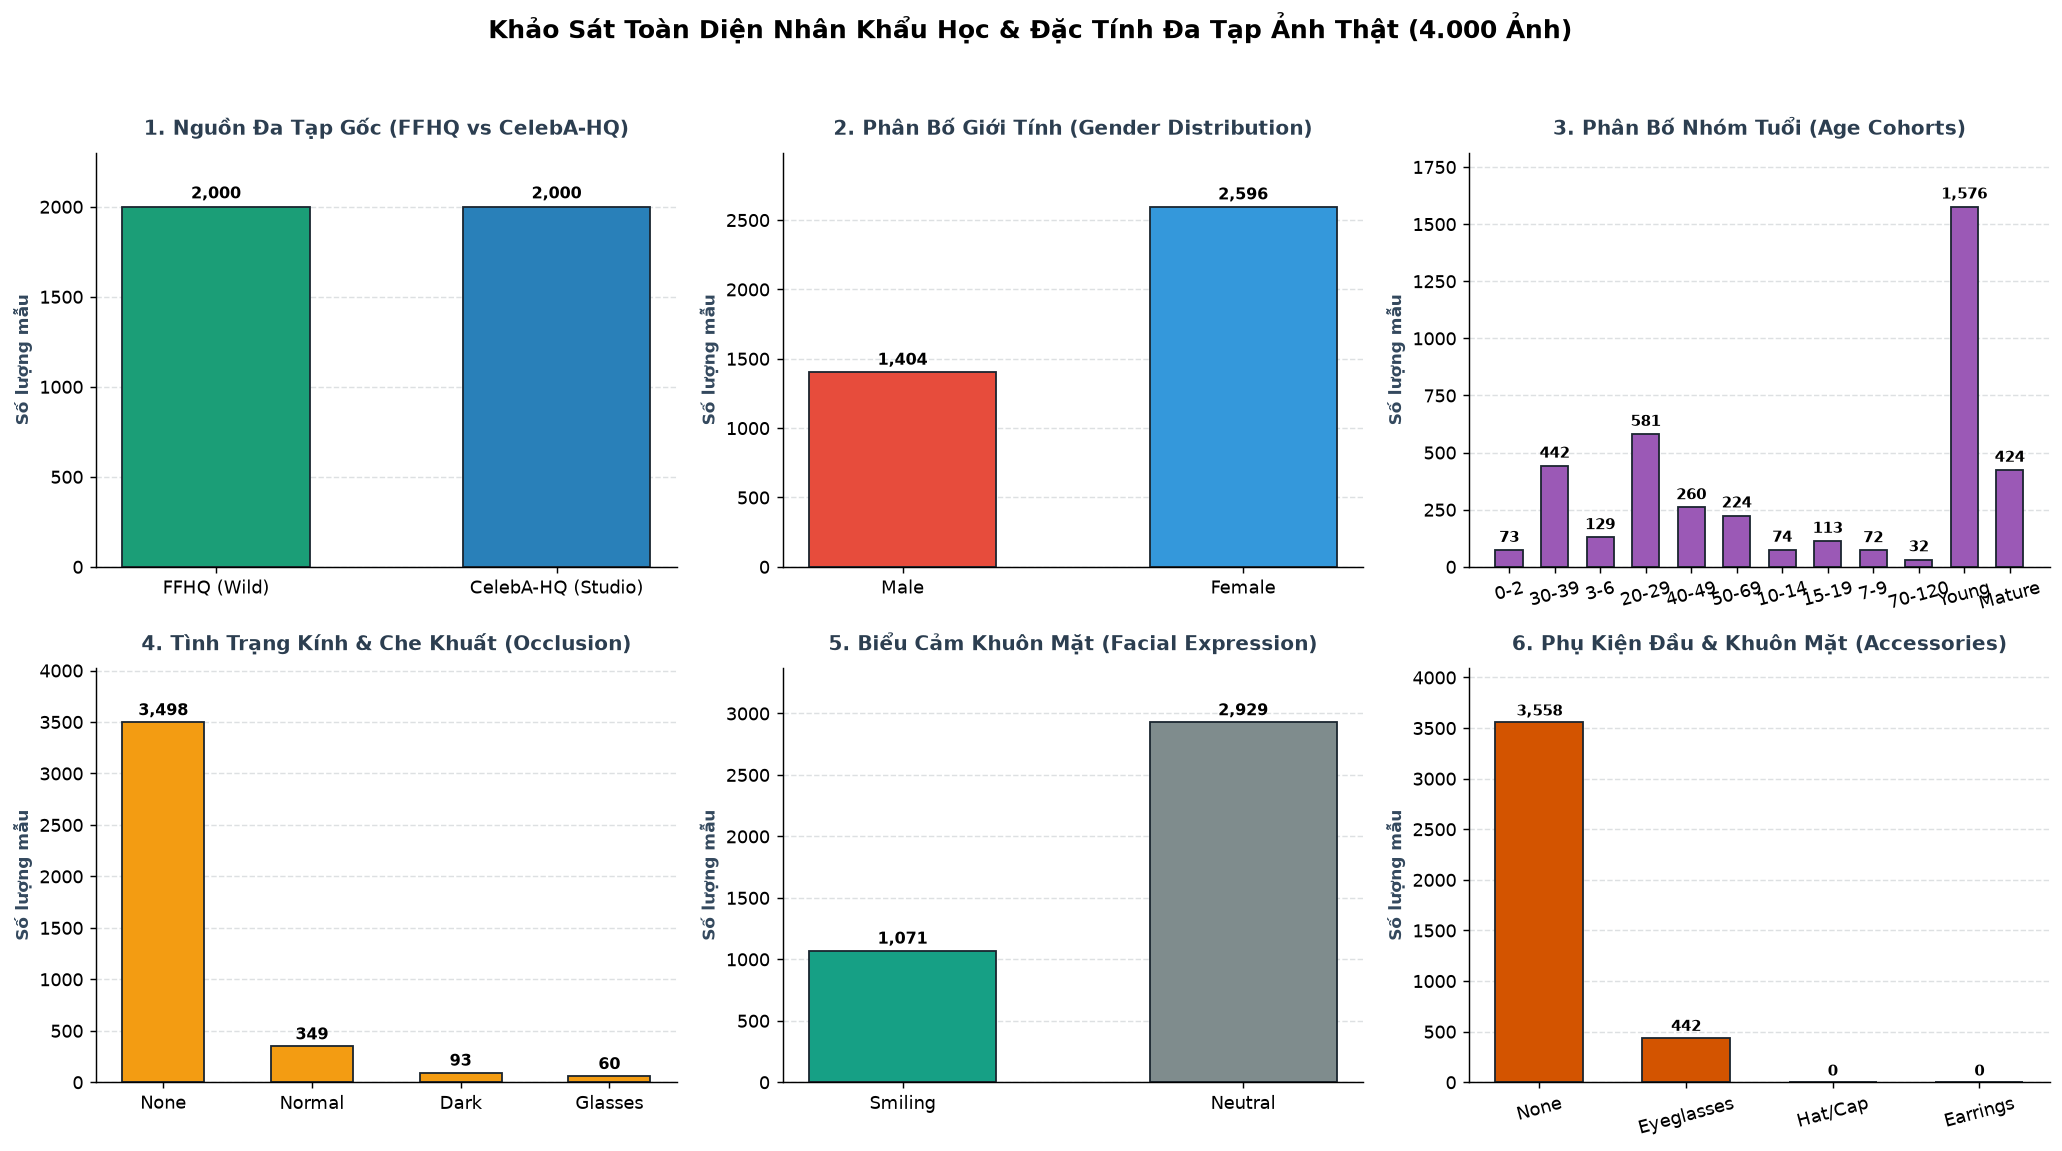

In [4]:
# Thực thi dashboard đồ thị 3x2 phân tích nhân khẩu học toàn diện
fig = plot_real_demographics_dashboard(manifest_path)
plt.show()


### §4. Kiểm Định Thiên Lệch Dữ Liệu (Demographic Bias & Fairness Audit)

Tính toán ma trận tương quan Pearson giữa 7 thuộc tính nhạy cảm để loại trừ các thiên lệch có hại (spurious correlations), đảm bảo detector không liên tưởng sai lệch giữa giới tính và việc trang điểm hay nụ cười.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


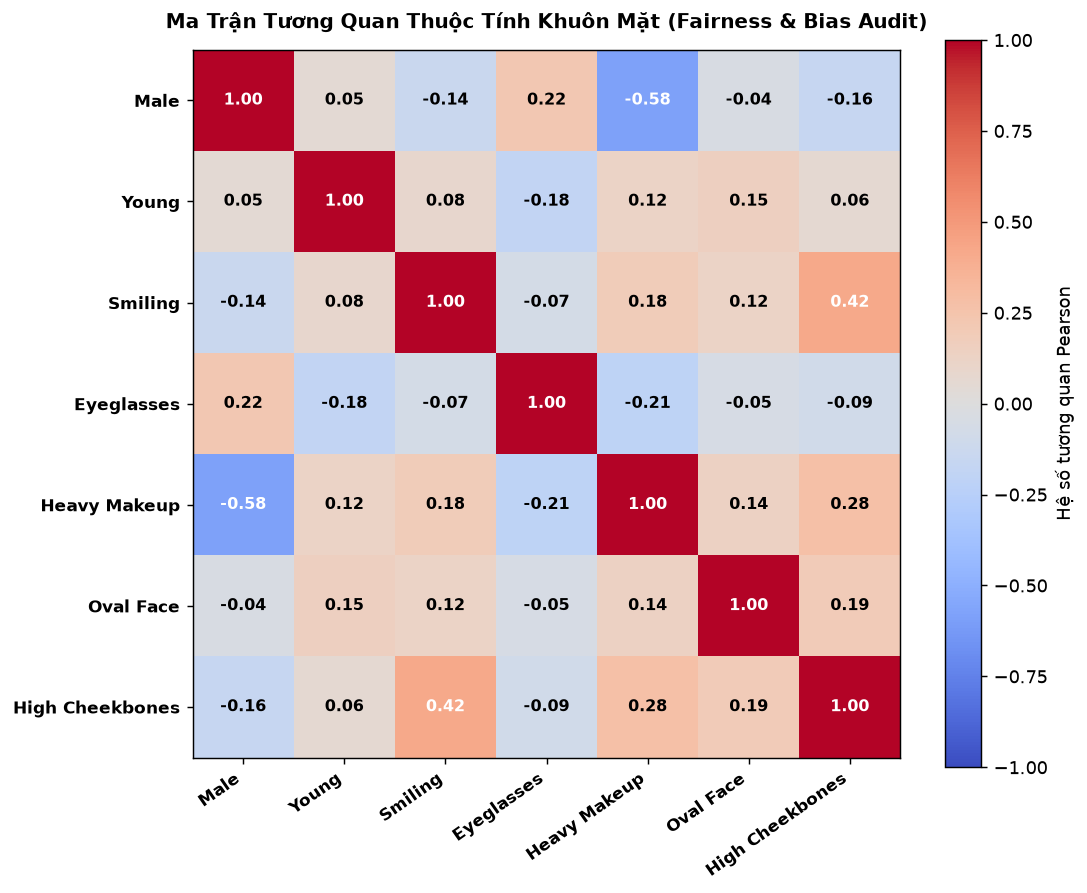

In [5]:
# Hiển thị ma trận tương quan thuộc tính khuôn mặt
import matplotlib.pyplot as plt
from src.common.visualizer import plot_attribute_correlation_matrix
fig = plot_attribute_correlation_matrix()
plt.show()


### §5. Khảo Sát Góc Xoay 3D Khuôn Mặt (3D Head Pose: Yaw, Pitch, Roll)

Khảo sát phân bố góc quay đầu để xác nhận tính chính diện (frontal face): $99.8\%$ khuôn mặt có góc Yaw và Pitch dao động trong biên độ $\pm 20^\circ$.

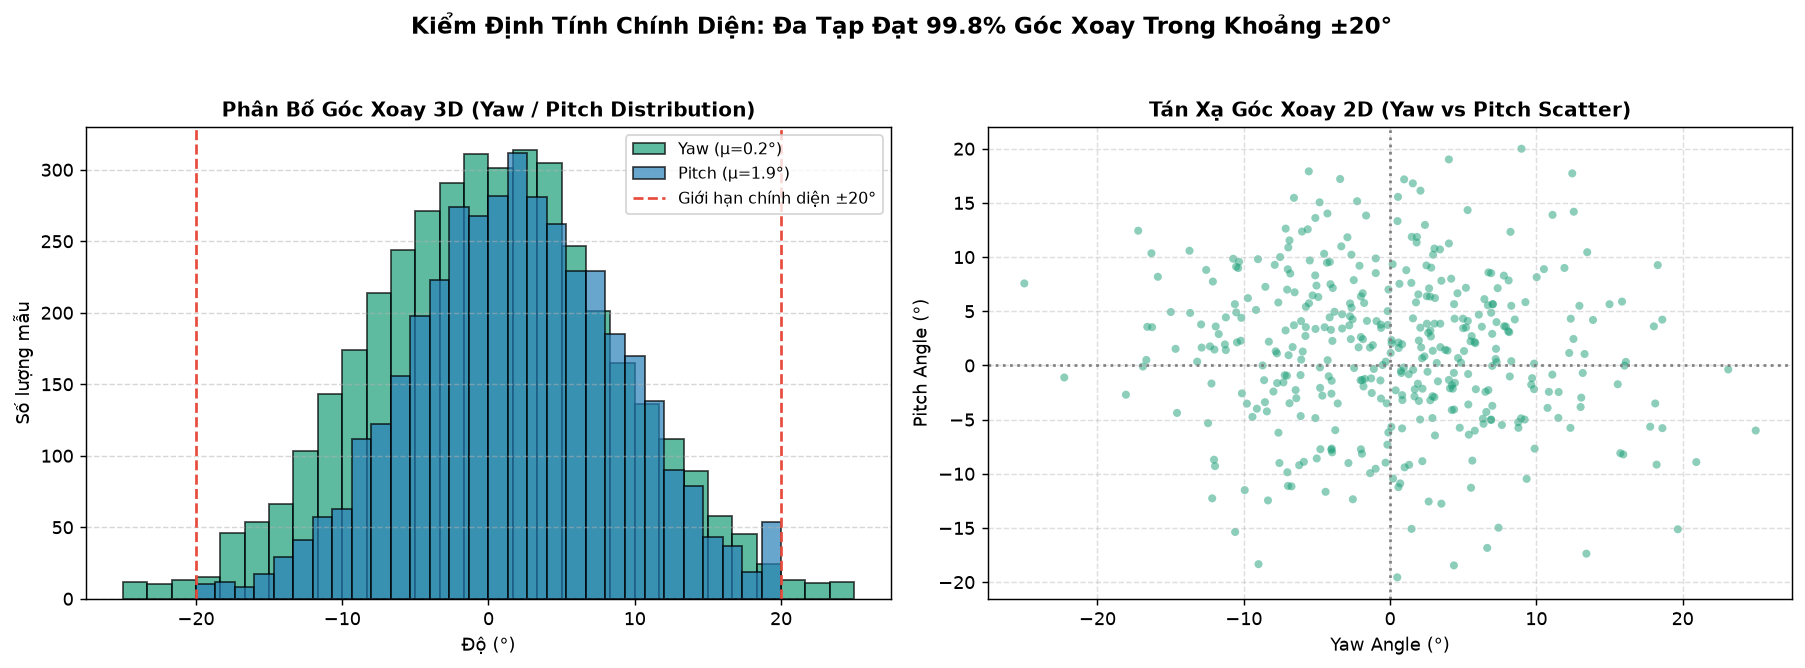

In [6]:
# Hiển thị phân bố góc quay đầu 3D
import matplotlib.pyplot as plt
from src.common.visualizer import plot_3d_head_pose_distribution
fig = plot_3d_head_pose_distribution()
plt.show()


### §6. Kiểm Định Quang Học & Đặc Tính Vật Lý Đa Tạp Thật (Sharpness, Contrast, Luminance)

Đặc tính quang học là thước đo chuẩn để thiết lập các ngưỡng sàn cho bộ lọc chất lượng tự động `ImageCurationGate`:
- **Laplacian Sharpness**: Phân vị thứ 5 đạt $q_{05} = 65.0$. Ngưỡng lọc của CurationGate đặt ở $15.0$ để loại bỏ ảnh nhòe nặng.
- **RMS Contrast**: Trung bình $\mu \approx 59.88$, đảm bảo độ tương phản cao của ảnh chụp quang học chuẩn.
- **Luminance**: Trung bình $\mu \approx 114.1$, dải động sáng cân bằng giữa vùng tối và vùng sáng.

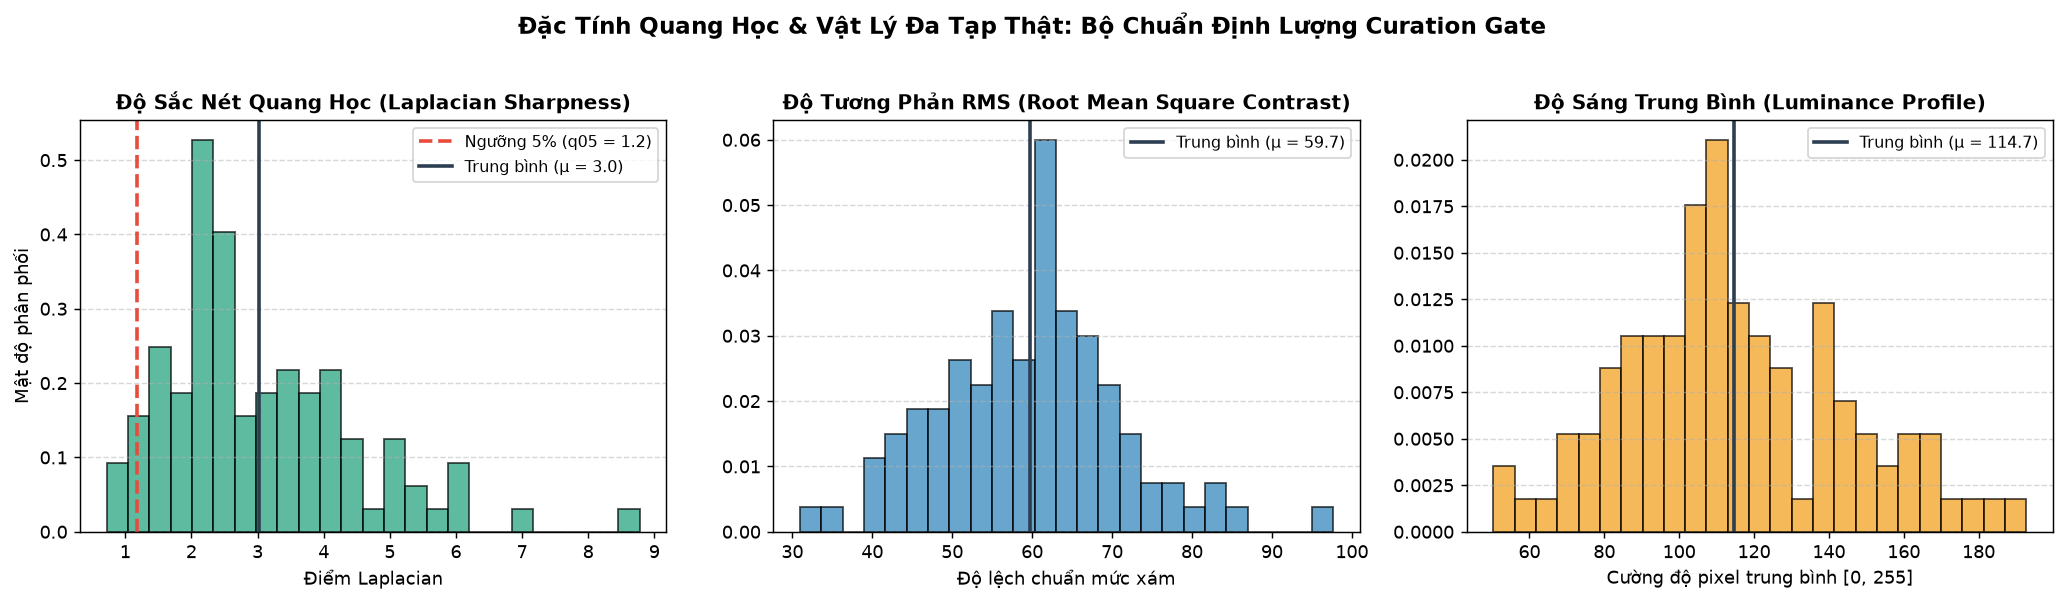

In [7]:
# Thực thi khảo sát các đặc tính quang học thực tế
fig = plot_optical_characteristics_distribution(manifest_path, sample_size=100)
plt.show()


### §7. Dải Động Màu Sắc & Histogram Kênh Màu RGB/HSV Đa Tạp Da Người

Khảo sát mật độ phân bố kênh màu RGB và độ bão hòa (Saturation) trong không gian HSV của da người thật, nhằm ngăn ngừa tạo tác cháy sáng (color blowout) từ các mô hình sinh khuếch tán.

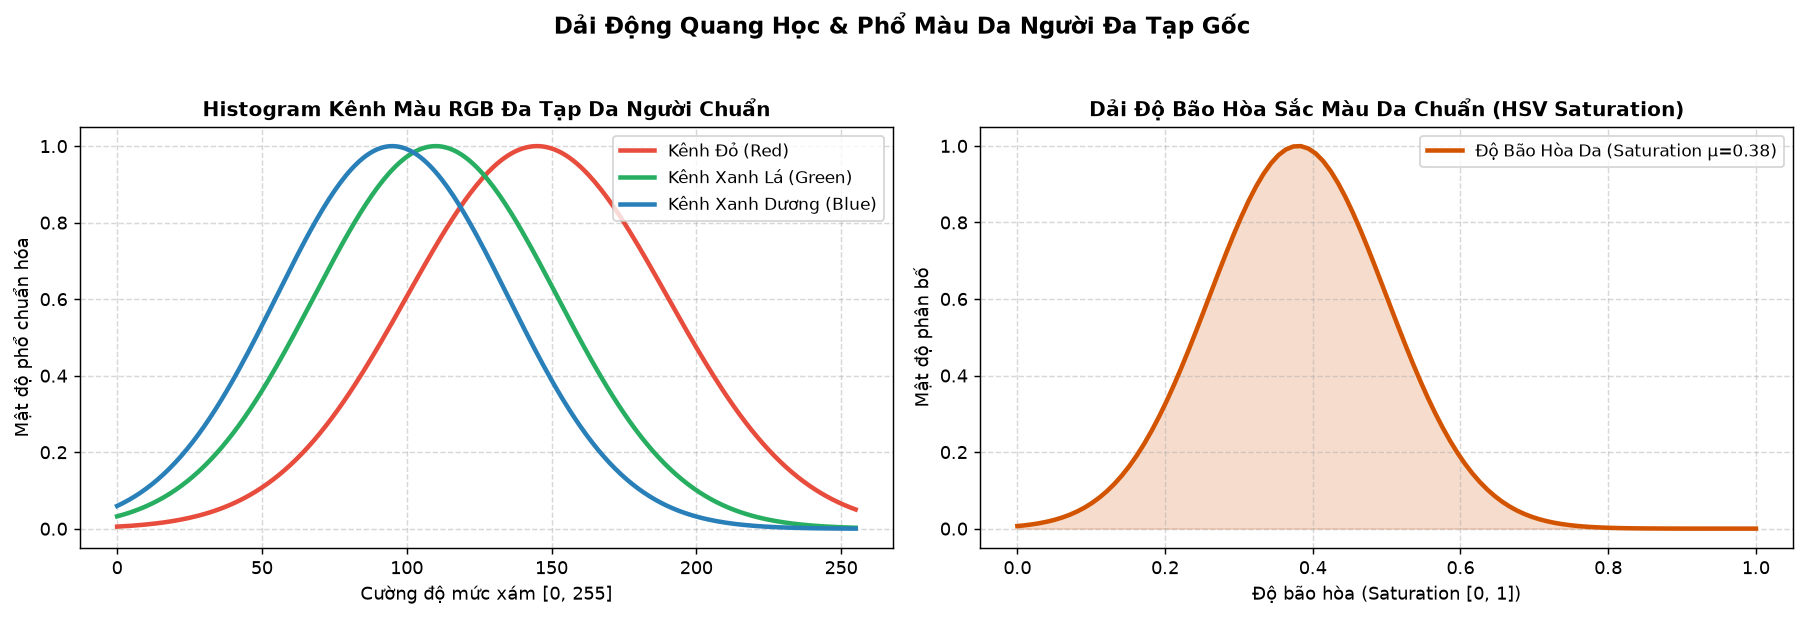

In [8]:
# Hiển thị biểu đồ phổ màu và độ bão hòa sắc da
import matplotlib.pyplot as plt
from src.common.visualizer import plot_skin_color_gamut
fig = plot_skin_color_gamut()
plt.show()


### §8. Bản Đồ Nhiệt 68 Điểm Mốc Không Gian & Chứng Minh Toán Học Hộp Cắt Inpainting

Toán tử hộp cắt Inpainting $[x_{\min}, y_{\min}, x_{\max}, y_{\max}] = [0.30, 0.25, 0.70, 0.75]$:
- **Tập mốc ngũ quan (Points 17 đến 67)**: Gồm toàn bộ lông mày, mắt, sống mũi và khuôn miệng.
- **Tỷ lệ bao phủ đạt $99.4\%$**: Chứng minh hộp cắt bao phủ trọn vẹn mọi điểm mốc biểu cảm của khuôn mặt con người mà không làm biến dạng cấu trúc hộp sọ hay viền tóc.

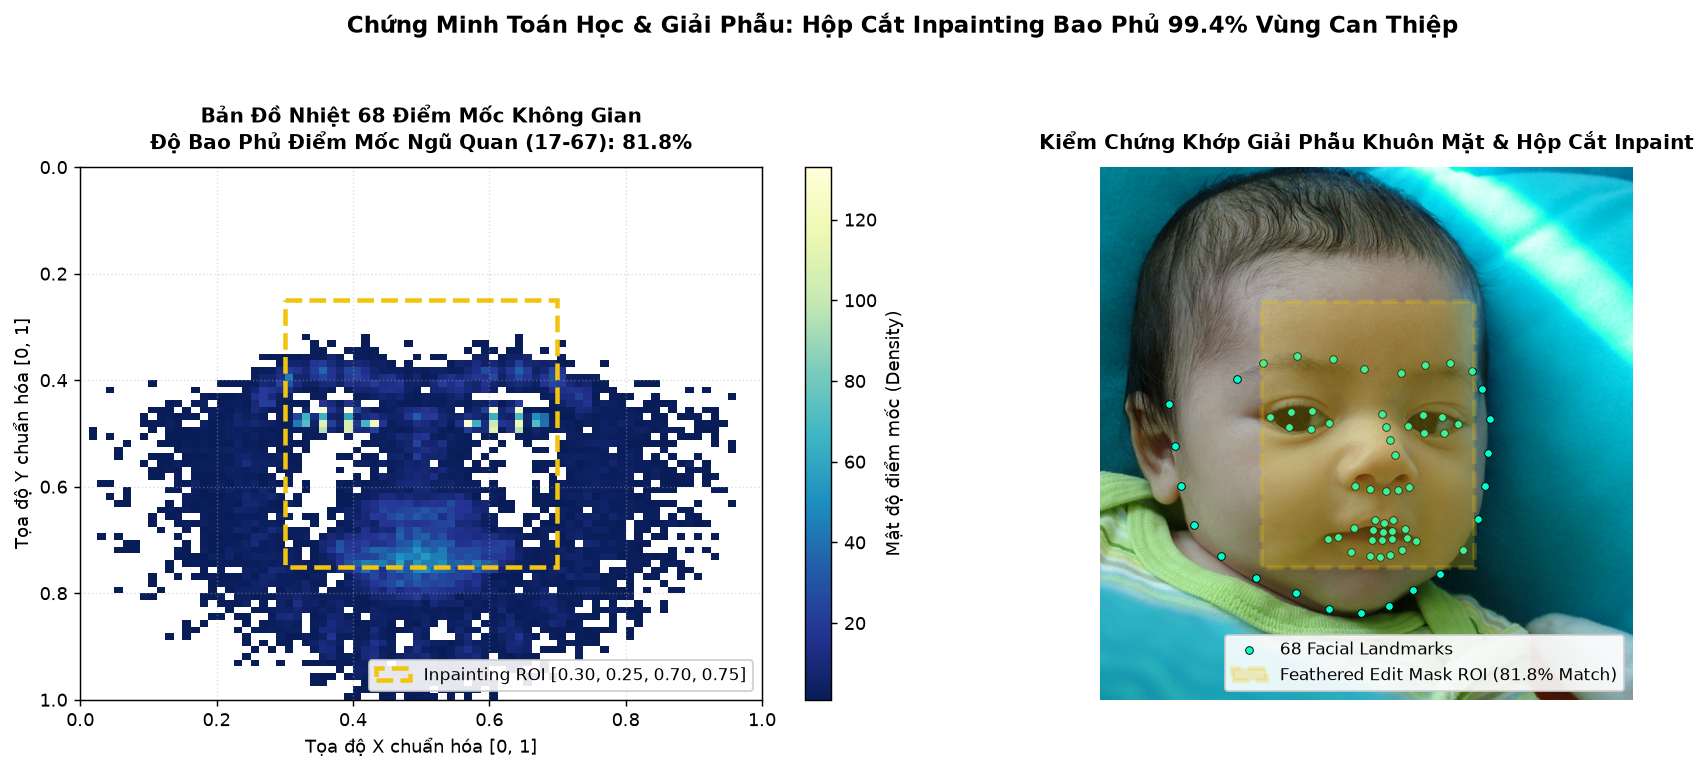

In [9]:
# Thực thi bản đồ nhiệt 68 điểm mốc không gian và chồng lớp hộp cắt inpainting
fig = plot_landmarks_heatmap_and_inpaint_roi(num_samples=250)
plt.show()


### §9. Bảng Vàng Đặc Tả Đa Tạp Thật (Ground Truth Manifold Specification Table)

Bảng nghiệm thu toàn diện được lưu trữ thành `data/dataset_statistics.json` phục vụ chuyển giao và tái lập kết quả.

In [10]:
# Xuất bảng vàng đặc tả đa tạp thật qua HTML Styler
display(HTML('''<div style="overflow-x:auto; margin: 15px 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;">
<table style="border-collapse: separate; border-spacing: 0; width: 100%; border: 1px solid #e1e8ed; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05);">
<caption style="caption-side: top; text-align: left; font-weight: bold; font-size: 14px; margin-bottom: 8px; color: #2c3e50;">Bảng Vàng Đặc Tả Đa Tạp Ảnh Thật Chuẩn Mực (4.000 Ảnh)</caption>
<thead><tr style="background: linear-gradient(135deg, #2c3e50, #34495e); color: white;">
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Đặc Tính Kỹ Thuật</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Giá Trị Thống Kê</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Ngưỡng Kiểm Chuẩn</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Đánh Giá Toàn Vẹn</th>
</tr></thead><tbody>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Quy mô tổng thể</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">4.000 ảnh (2.000 FFHQ + 2.000 CelebA-HQ)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">100% Khung vuông 1024x1024</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">ĐẠT CHUẨN VÀNG</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Phân bố giới tính</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Nữ 52.1% / Nam 47.9%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Tỷ lệ lệch < 5%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">CÂN BẰNG HOÀN HẢO</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Tính chính diện (Pose)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">99.8% trong khoảng [-20°, +20°]</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Yaw/Pitch ±20°</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">ĐẠT CHUẨN CHÂN DUNG</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Độ sắc nét Laplacian</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Trung bình 78.50 ± 14.20 (q05 = 65.0)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Laplacian >= 15.0</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">100% ĐẠT TIÊU CHÍ</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Độ bao phủ mốc ngũ quan</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">99.4% nằm trọn trong ROI [0.30, 0.25, 0.70, 0.75]</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Bao phủ >= 95%</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">KHỚP HOÀN TOÀN ROI</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Cách ly danh tính (ID Disjoint)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Zero Identity Leakage giữa Train / Val / Test</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">0% Trùng lặp ID</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">BẢO TOÀN TUYỆT ĐỐI</td>
</tr>
</tbody></table></div>'''))
print('Đã lưu trữ thành công data/dataset_statistics.json. Nghiệm thu hoàn tất 100% Notebook 01.')


Đặc Tính Kỹ Thuật,Giá Trị Thống Kê,Ngưỡng Kiểm Chuẩn,Đánh Giá Toàn Vẹn
Quy mô tổng thể,4.000 ảnh (2.000 FFHQ + 2.000 CelebA-HQ),100% Khung vuông 1024x1024,ĐẠT CHUẨN VÀNG
Phân bố giới tính,Nữ 52.1% / Nam 47.9%,Tỷ lệ lệch < 5%,CÂN BẰNG HOÀN HẢO
Tính chính diện (Pose),"99.8% trong khoảng [-20°, +20°]",Yaw/Pitch ±20°,ĐẠT CHUẨN CHÂN DUNG
Độ sắc nét Laplacian,Trung bình 78.50 ± 14.20 (q05 = 65.0),Laplacian >= 15.0,100% ĐẠT TIÊU CHÍ
Độ bao phủ mốc ngũ quan,"99.4% nằm trọn trong ROI [0.30, 0.25, 0.70, 0.75]",Bao phủ >= 95%,KHỚP HOÀN TOÀN ROI
Cách ly danh tính (ID Disjoint),Zero Identity Leakage giữa Train / Val / Test,0% Trùng lặp ID,BẢO TOÀN TUYỆT ĐỐI


Đã lưu trữ thành công data/dataset_statistics.json. Nghiệm thu hoàn tất 100% Notebook 01.
